# Project data exploration - looking at relplot and scatter plots
Using a dataset that your group is consider using for the term project, let's do some data exploring of the different features in your dataset and their relationships

Group name:  
Created by Sofie Jensen (016964220), Nyi Htet (), Javier Aguilar Ochoa (016486301)  
Last updated: 10/25/2026  
Briefly describe your dataset:  
Our dataset contains real Amazon sales data for the U.S. over about 4 years and we are using it as a marketing analytics resource.

Import your data. If you want to mount your Google drive you can use `from google.colab import drive` and `drive.mount('/content/drive')`

## Q1: Data background
Provide a brief summary of the data including source, size of data, topic, and what the motivation behind exploring this dataset.

This dataset contains 3203 rows (not including header) and 10 columns about real Amazon product sales in the U.S. from January 7th, 2011 to December 31st, 2014.  
The columns include:  
Order ID, Order Date, Ship Date, Email ID, Geography (customer location), Category (for product), Product Name, Sales, Quantity, Profit  
There is no a lot of explanation for why this creator chose to compile this data, but it is useful for our topic of marketing analytics.

This dataset comes from kaggle: https://www.kaggle.com/datasets/anandshaw2001/amazon-sales-dataset

### Q2: Show the number of missing data in each column of the dataframe
If you have missing data, how much? which column(s)? Do you think it will impact your output?

In [1]:
#!pip install openpyxl  #install if needed
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import io
from google.colab import files

In [2]:
uploaded = files.upload()
file_name = list(uploaded.keys())[0]
amazon_analysis = pd.read_excel(io.BytesIO(uploaded[file_name]))
amazon_analysis

Saving Amazon 2_Raw.xlsx to Amazon 2_Raw.xlsx


,Order ID,Order Date,Ship Date,EmailID,Geography,Category,Product Name,Sales,Quantity,Profit
0,CA-2013-138688,2013-06-13,2013-06-17,DarrinVanHuff@gmail.com,"United States,Los Angeles,California",Labels,Self-Adhesive Address Labels for Typewriters b...,14.620,2,6.8714
1,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.860,7,14.1694
2,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Art,Newell 322,7.280,4,1.9656
3,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Phones,Mitel 5320 IP Phone VoIP phone,907.152,4,90.7152
4,CA-2011-115812,2011-06-09,2011-06-14,BrosinaHoffman@gmail.com,"United States,Los Angeles,California",Binders,DXL Angle-View Binders with Locking Rings by S...,18.504,3,5.7825
...,...,...,...,...,...,...,...,...,...,...
3198,CA-2013-125794,2013-09-30,2013-10-04,MarisLaWare@gmail.com,"United States,Los Angeles,California",Accessories,Memorex Mini Travel Drive 64 GB USB 2.0 Flash ...,36.240,1,15.2208
3199,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Furnishings,Tenex B1-RE Series Chair Mats for Low Pile Car...,91.960,2,15.6332
3200,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Phones,Aastra 57i VoIP phone,258.576,2,19.3932
3201,CA-2014-121258,2014-02-27,2014-03-04,DaveBrooks@gmail.com,"United States,Costa Mesa,California",Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.600,4,13.3200


In [3]:
amazon_analysis.rename(columns={"EmailID":"Email ID"}, inplace=True)
amazon_analysis.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3203 entries, 0 to 3202
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Order ID      3203 non-null   object        
 1   Order Date    3203 non-null   datetime64[ns]
 2   Ship Date     3203 non-null   datetime64[ns]
 3   Email ID      3203 non-null   object        
 4   Geography     3203 non-null   object        
 5   Category      3203 non-null   object        
 6   Product Name  3203 non-null   object        
 7   Sales         3203 non-null   float64       
 8   Quantity      3203 non-null   int64         
 9   Profit        3203 non-null   float64       
dtypes: datetime64[ns](2), float64(2), int64(1), object(5)
memory usage: 250.4+ KB


In [4]:
amazon_analysis.describe()

,Order Date,Ship Date,Sales,Quantity,Profit
count,3203,3203,3203.000000,3203.000000,3203.000000
mean,2013-05-10 03:06:07.530440192,2013-05-14 01:25:25.195129600,226.493233,3.828910,33.849032
min,2011-01-07 00:00:00,2011-01-09 00:00:00,0.990000,1.000000,-3399.980000
25%,2012-05-22 00:00:00,2012-05-26 00:00:00,19.440000,2.000000,3.852000
50%,2013-07-22 00:00:00,2013-07-25 00:00:00,60.840000,3.000000,11.166400
75%,2014-05-23 00:00:00,2014-05-27 00:00:00,215.809000,5.000000,33.000400
max,2014-12-31 00:00:00,2015-01-06 00:00:00,13999.960000,14.000000,6719.980800
std,NaN,NaN,524.876877,2.260947,174.109081


There doesn't seem to be any missing data or null values. However, in ```amazon_analysis.describe()```, std returns NaN for Order Date and Ship Date, but this is probably because those columns have a non-numerical format. They are datetime64 data types, so if we want to use them as strings or split them into month, day, year columns, then we will need to convert them accordingly.



### Q3: Show the data type for each column of the dataframe
Is the data type as expected? Is it clear what the content/value of each column is?

In [5]:
amazon_analysis.dtypes

,0
Order ID,object
Order Date,datetime64[ns]
Ship Date,datetime64[ns]
Email ID,object
Geography,object
Category,object
Product Name,object
Sales,float64
Quantity,int64
Profit,float64


Each data type makes sense for each column, but Order Date and Ship Date will be difficult to work with given they are datetime64 dtypes. However, we may be able to use those columns as is, but it does change some of our strategies.

### Q4: Your own question using `relplot()`
Come up with your own question to do the initital exploration of your data that utilizes the `relplot()` package to understand relationships between two variables.  
#### Question for `relplot()`
1. Is there a relationship between sales and profit, and does that relationship differ across product categories?

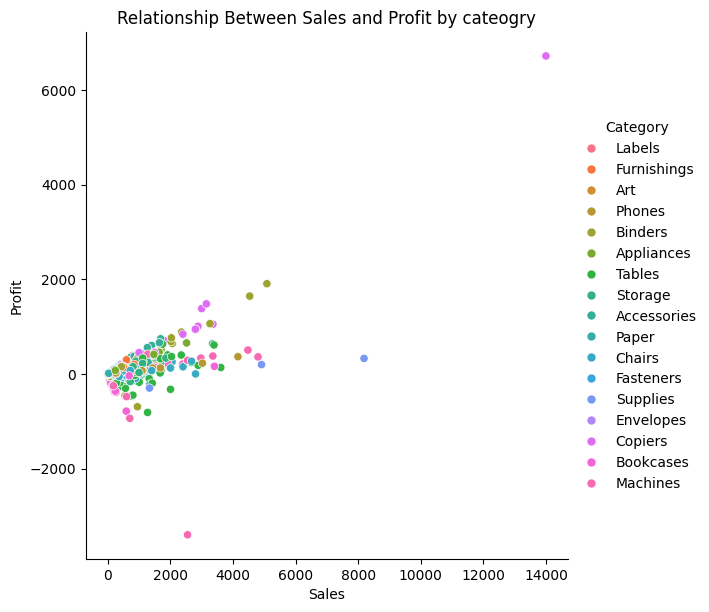

In [6]:
# Your code here . . .
sns.relplot(
    data=amazon_analysis,
    x="Sales",
    y="Profit",
    hue="Category",
    kind="scatter",
    height=6,
    aspect=1
)

plt.title("Relationship Between Sales and Profit by cateogry")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.show()

The graph seems to show a positive relationship between sales and profit, the products with higher sales seem to have higher profits. However, some outliers suggest that higher sales do not guarantee profitability so the relationship is not perfect. Profitability also seems to vary across product categories some categories show more variation and inconsistency than others.

### Q5: Your own question using `catplot()`
Come up with your own question to do the initital exploration of your data that utilizes the `catplot()` package to understand categorical variables in your dataset.
#### Question for `catplot()`
1. What is the trend for the quantity of each product category sold to Californians?


In [14]:
# Split Geography into parts (Country, City, State)
geo_split = amazon_analysis["Geography"].str.split(",", expand=True)

# Assign the 3rd part as the new 'State' column
amazon_analysis["State"] = geo_split[2]

# Assign the 2nd part as the new 'City' column
amazon_analysis["City"] = geo_split[1]

amazon_analysis.loc[:,["State", "City", "Geography"]].value_counts()

State       City           Geography                             
California  Los Angeles    United States,Los Angeles,California      747
            San Francisco  United States,San Francisco,California    510
Washington  Seattle        United States,Seattle,Washington          428
California  San Diego      United States,San Diego,California        170
Arizona     Phoenix        United States,Phoenix,Arizona              63
                                                                    ... 
Idaho       Lewiston       United States,Lewiston,Idaho                1
Washington  Auburn         United States,Auburn,Washington             1
Utah        Layton         United States,Layton,Utah                   1
Washington  Everett        United States,Everett,Washington            1
Wyoming     Cheyenne       United States,Cheyenne,Wyoming              1
Name: count, Length: 170, dtype: int64

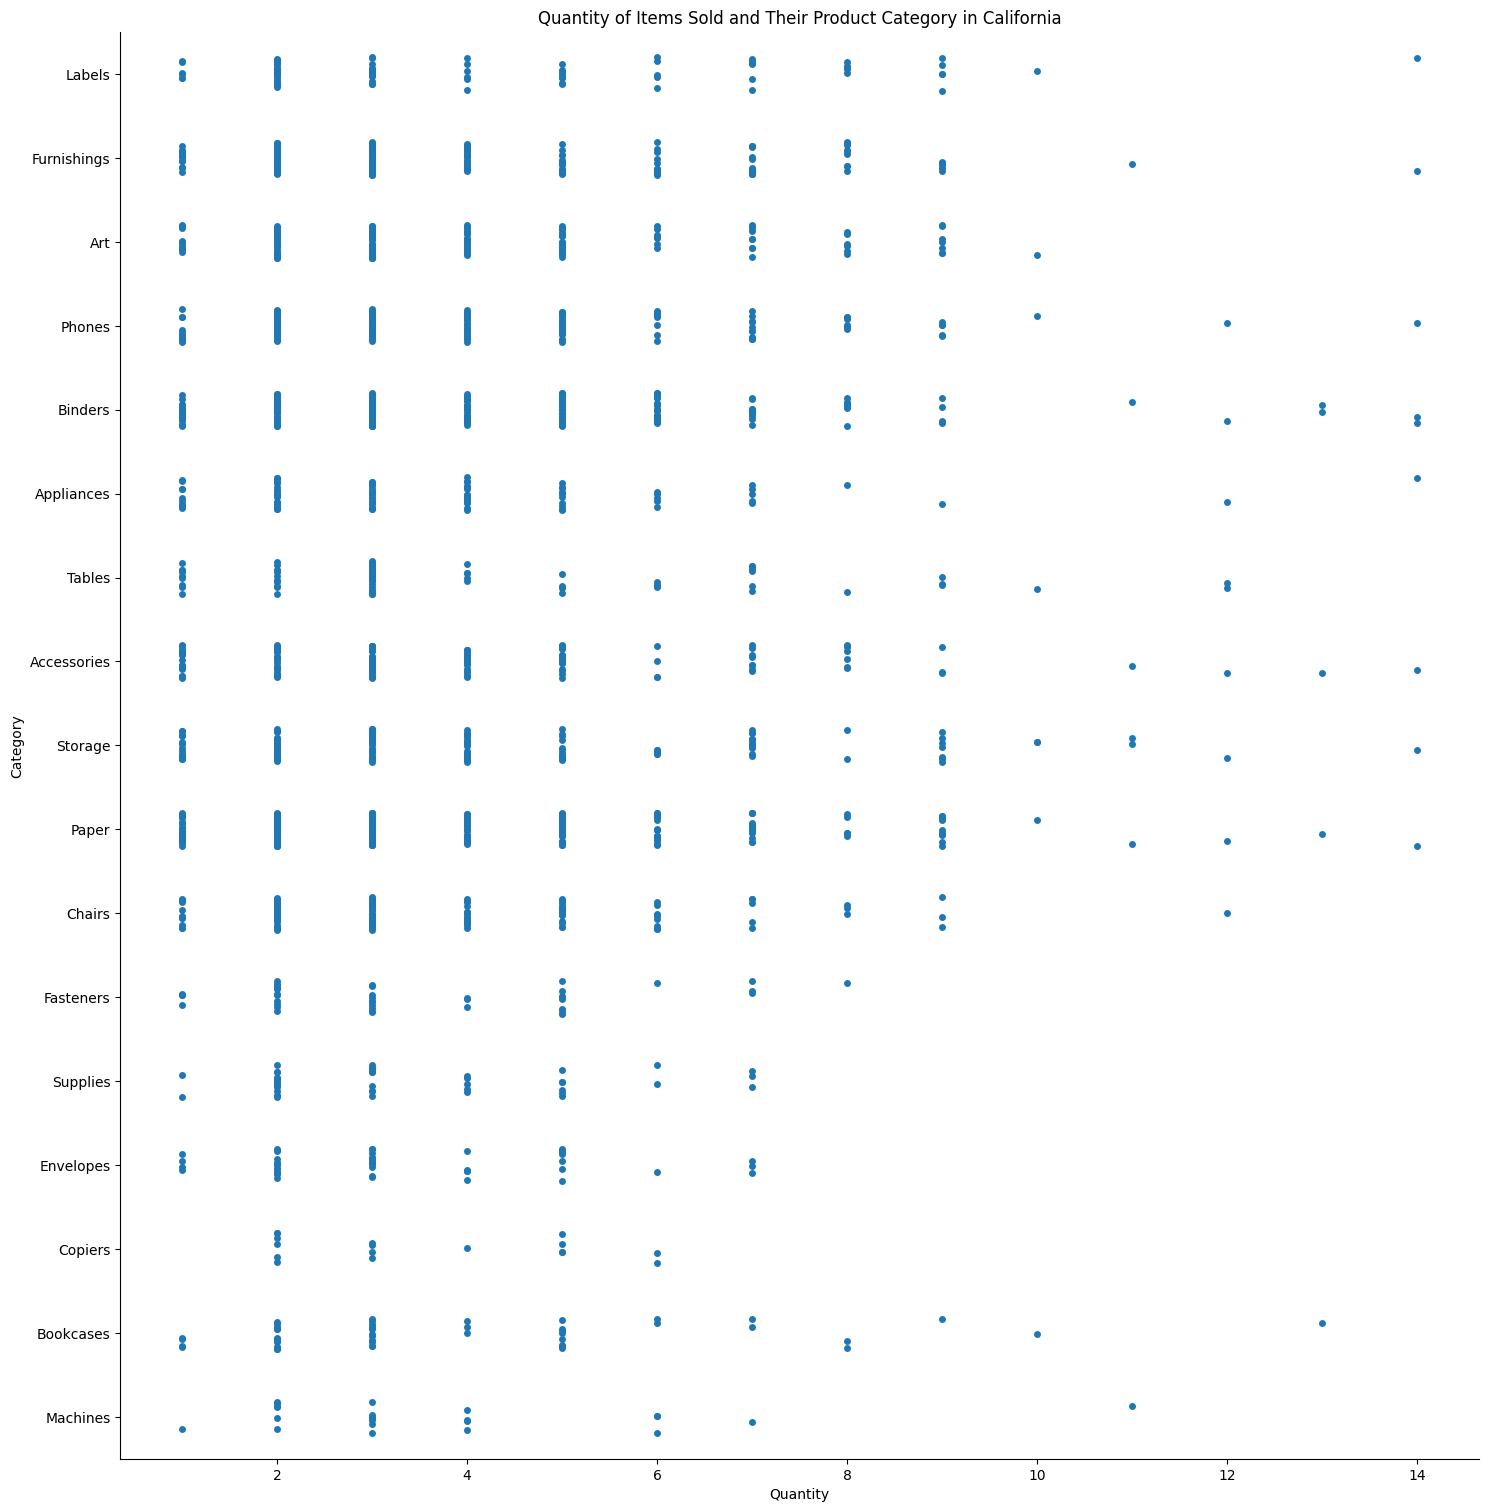

In [38]:
cali_cat = amazon_analysis[amazon_analysis["State"] == "California"]
sns.catplot(
    data = cali_cat,
    x = "Quantity",
    y = "Category",
    aspect = 1, # aspect change the aspect ratio
    height = 15,
    jitter = 0.2, # jitter spread out the data points
    kind="strip"
    #hue="State"
    )
plt.title("Quantity of Items Sold and Their Product Category in California");

We can see from the plot above that most people in California will stop at a quantity of 5 to 7 items within any given product category. Almost no one buys 10 items or more of anything. Most people tend to buy 3 items within any category. People in California also tend to buy more than 1 item in the Machines, Bookcases, Copiers, Supplies, Fasteners, and Labels product category.

### Q6: Create a plot with small multiples plots
Select two features from your dataset and show the relationship between the features with an additional feature as the single category. Organize the multiple plots to have 3 plots per row. Set the `height` of the plot to 5 and the size the of data point to 20. Include a meaningful title in the plot.
#### Possible Questions for small multiple plots
1. For each product category, what is the most sold product?
2. For each product category, what is the least sold product?
3. Which one has the most quantity sold, but have most profit ?
3. Which one has the most quantity sold, but have least profit ?

Final Choice:

For each product category, what is the relationship between quantity and profit?

In [ ]:
# Your code here . . .

